1. Desarrollar una función basada en ciclos que permita
aplicar un filtro ideal pasa bajos en 2D. Recibe como
entrada la imagen original y la frecuencia de corte.
Probar el algoritmo con las imágenes “rectOne.pgm”,
“nebulosaLira.pgm” y “gwen-pgm” con diversas
frecuencias de corte.

2. Desarrollar una función basada en ciclos que permita
aplicar un filtro Butterworth en 2D. Recibe como
entrada la imagen original, la frecuencia de corte y el
orden del filtro. Probar el algoritmo con las imágenes
“rectOne.pgm”, “nebulosaLira.pgm” y “gwen.pgm”
con diversas frecuencias de corte y diferente orden

3. Desarrollar una función basada en ciclos que permita
aplicar un filtro Gaussian en 2D. Recibe como
entrada la imagen original y la frecuencia de corte.
Probar el algoritmo con las imágenes “rectOne.pgm”,
“nebulosaLira.pgm” y “gwen-pgm” con diversas
frecuencias de corte.

4. Desarrollar una función basada en ciclos que permita
aplicar un filtro ideal pasa altos en 2D. Recibe como
entrada la imagen original y la frecuencia de corte.
Probar el algoritmo con las imágenes “rectOne.pgm”,
“nebulosaLira.pgm” y “gwen-pgm” con diversas
frecuencias de corte.

5. Desarrollar una función basada en ciclos que permita
aplicar un filtro pasa altos Butterworth en 2D. Recibe
como entrada la imagen original, la frecuencia de
corte y el orden del filtro. Probar el algoritmo con las
imágenes “rectOne.pgm”, “nebulosaLira.pgm” y
“gwen.pgm” con diversas frecuencias de corte y
diferente orden.

6. Desarrollar una función basada en ciclos que permita
aplicar un filtro pasa altos Gaussian en 2D. Recibe
como entrada la imagen original y la frecuencia de
corte. Probar el algoritmo con las imágenes
“rectOne.pgm”, “nebulosaLira.pgm” y “gwen-pgm”
con diversas frecuencias de corte.

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import os
import cv2

os.makedirs('results', exist_ok=True)

## Punto 1 
Desarrollar una función basada en ciclos que permita
aplicar un filtro ideal pasa bajos en 2D. Recibe como
entrada la imagen original y la frecuencia de corte.
Probar el algoritmo con las imágenes “rectOne.pgm”,
“nebulosaLira.pgm” y “gwen-pgm” con diversas
frecuencias de corte.

In [13]:
def filtro_ideal_paso_bajo(imagen, frecuencia_corte):
    if frecuencia_corte <= 0:
        raise ValueError("La frecuencia de corte debe ser mayor que cero.")

    # Obtener las dimensiones de la imagen
    filas, columnas = imagen.shape

    # Paso 1: Transformada de Fourier de la imagen
    transformada = np.fft.fft2(imagen)

    # Centrar las frecuencias
    transformada_centrada = np.fft.fftshift(transformada)

    # paso 2: Crear el filtro ideal de paso bajo, mascara ideal
    mascara = np.zeros((filas, columnas), dtype=np.float64)

    # Calcular el centro de la imagen
    centro_fila, centro_columna = filas // 2, columnas // 2

    for fila in range(filas):
        for columna in range(columnas):
            # Calcular la distancia desde el centro
            distancia = np.sqrt((fila - centro_fila) ** 2 + (columna - centro_columna) ** 2)
            if distancia <= frecuencia_corte:
                mascara[fila, columna] = 1
    # paso 3: Aplicar el filtro a la transformada centrada
    transformada_filtrada = transformada_centrada * mascara

    # paso 4: Transformada inversa de Fourier, regresar al dominio espacial
    transformada_inversa = np.fft.ifftshift(transformada_filtrada)

    imagen_filtrada = np.fft.ifft2(transformada_inversa)

    # paso 5: Tomar la parte real de la imagen filtrada
    imagen_filtrada_real = np.real(imagen_filtrada)

    return imagen_filtrada_real,mascara


In [14]:
# Cuadrado sintético de 256x256
cuadrado = np.zeros((256, 256), dtype=np.float64)
cuadrado[64:192, 64:192] = 255

# Fotografías en escala de grises
rostro = cv2.imread("images/rostro.png", cv2.IMREAD_GRAYSCALE)
paisaje = cv2.imread("images/paisaje.png", cv2.IMREAD_GRAYSCALE)

if rostro is None or paisaje is None:
    raise FileNotFoundError(
        "No se encontró alguna de las imágenes."
    )

imagenes = [cuadrado, rostro, paisaje]
titulos = ["Cuadrado", "Rostro", "Paisaje"]

for titulo, img in zip(titulos, imagenes):
    print(f"{titulo}: {img.shape}")

Cuadrado: (256, 256)
Rostro: (1200, 1200)
Paisaje: (533, 800)


In [15]:
frecuencias = [20, 40, 80]

resultados = {}

for titulo, imagen_actual in zip(titulos, imagenes):

    resultados[titulo] = {}

    for corte in frecuencias:

        filtrada, mascara = filtro_ideal_paso_bajo(
            imagen_actual, corte
        )

        resultados[titulo][corte] = {
            "imagen": filtrada,
            "mascara": mascara
        }

    print(f"{titulo}: filtros aplicados correctamente")

Cuadrado: filtros aplicados correctamente
Rostro: filtros aplicados correctamente
Paisaje: filtros aplicados correctamente


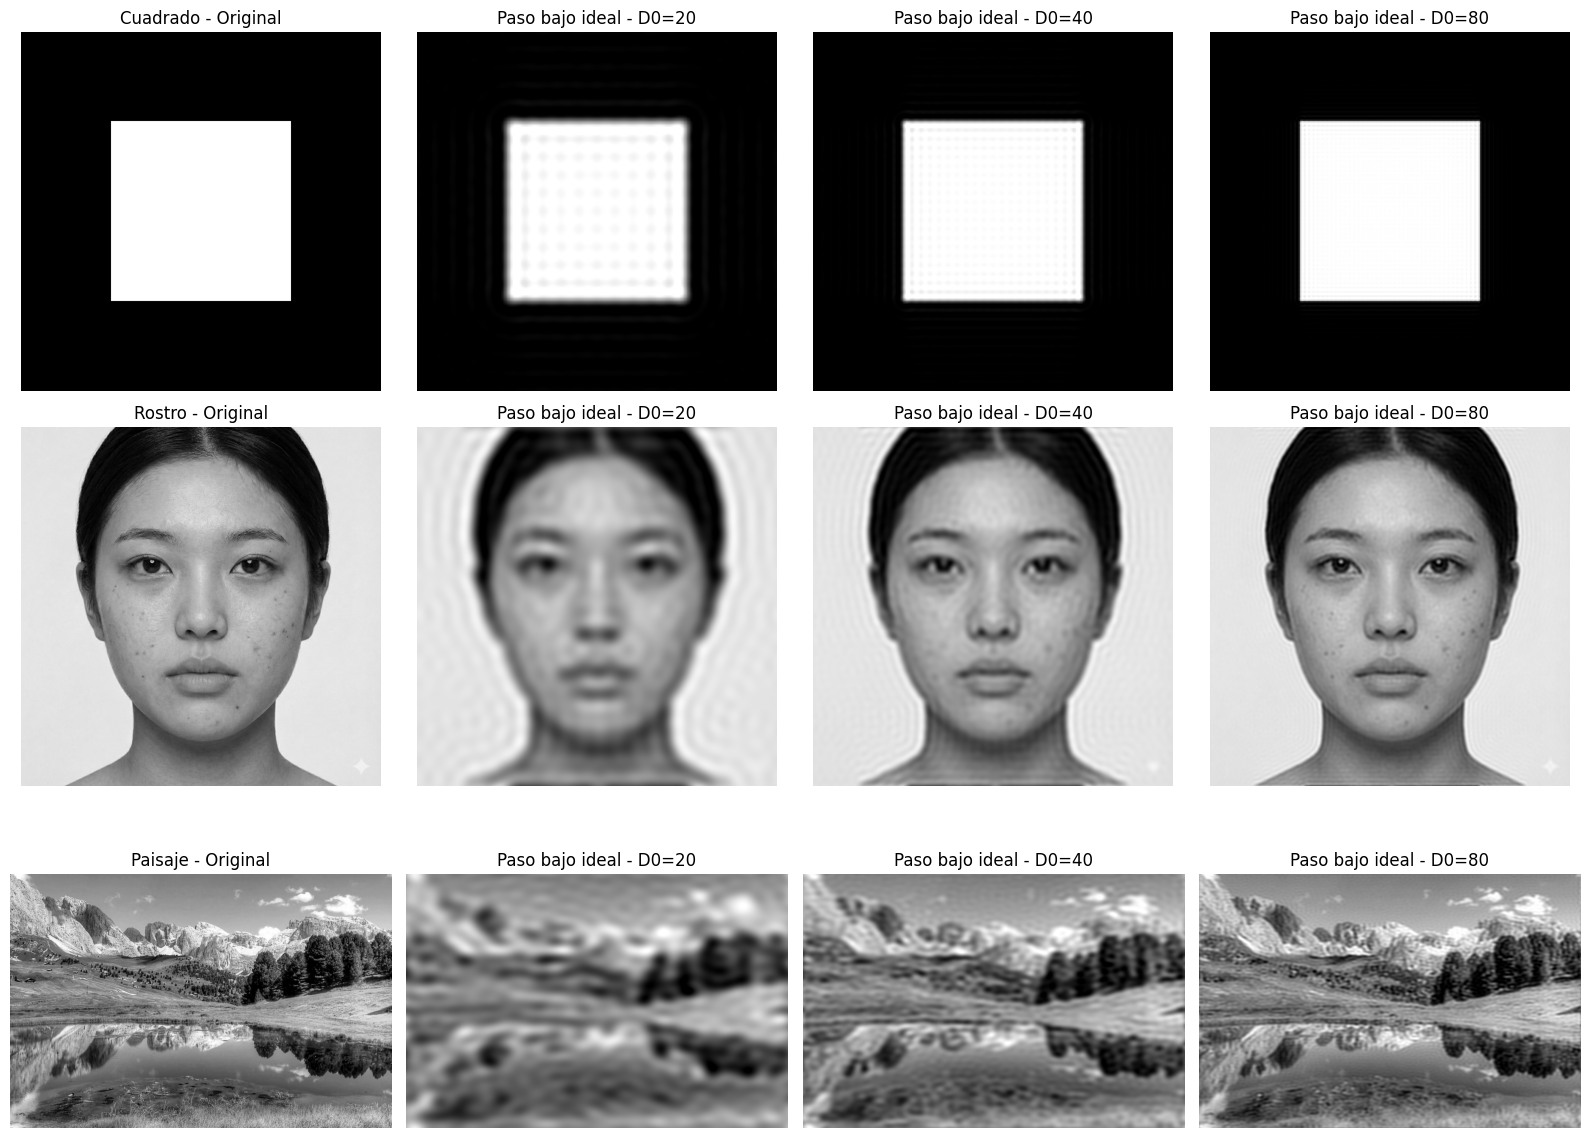

In [16]:
fig, axs = plt.subplots(3, 4, figsize=(16, 12))

for i, (titulo, imagen_actual) in enumerate(
    zip(titulos, imagenes)
):
    axs[i, 0].imshow(
        imagen_actual,
        cmap="gray",
        vmin=0,
        vmax=255
    )
    axs[i, 0].set_title(f"{titulo} - Original")
    axs[i, 0].axis("off")

    for j, corte in enumerate(frecuencias):

        imagen_filtrada = resultados[titulo][corte]["imagen"]

        axs[i, j + 1].imshow(
            imagen_filtrada,
            cmap="gray",
            vmin=0,
            vmax=255
        )

        axs[i, j + 1].set_title(f"Paso bajo ideal - D0={corte}")
        axs[i, j + 1].axis("off")

plt.tight_layout()
plt.savefig("results/filtro_ideal_paso_bajo.png")
plt.show()

### Análisis de resultados — Punto 1: Filtro ideal paso bajo

Se implementó un filtro ideal paso bajo en el dominio de la frecuencia mediante una función que recibe una imagen en escala de grises y una frecuencia de corte. La máscara del filtro se construyó utilizando ciclos anidados, calculando la distancia de cada posición respecto al centro del espectro.

El algoritmo se probó con tres imágenes: un cuadrado blanco sobre fondo negro, un rostro y un paisaje natural. Para cada imagen se utilizaron frecuencias de corte de 20, 40 y 80.

En la imagen del **cuadrado**, se observó que con una frecuencia de corte de 20 los bordes pierden definición y aparecen halos alrededor de la figura. Estos efectos disminuyen al aumentar la frecuencia de corte a 40 y 80, obteniendo bordes progresivamente más definidos.

En la imagen del **rostro**, el filtro con frecuencia de corte de 20 produce un suavizado considerable, reduciendo pequeñas variaciones de intensidad en la piel, pero también afectando la definición de los ojos, las cejas y el cabello. Al aumentar la frecuencia de corte, se recupera progresivamente la nitidez y se conservan más detalles. También se observan algunas bandas alrededor del contorno de la cabeza, relacionadas con el efecto de anillado del filtro ideal.

En el **paisaje**, el filtro con frecuencia de corte de 20 produce una pérdida notable de detalles en las montañas, los árboles y los reflejos del agua. Con una frecuencia de 40 se recuperan algunas texturas, mientras que con 80 la imagen conserva mayor definición y se aproxima más a la original.

Los resultados muestran que una frecuencia de corte menor produce un suavizado más intenso, debido a que se eliminan más componentes de alta frecuencia. Por el contrario, una frecuencia de corte mayor permite conservar más detalles.

También se evidenció el **efecto de anillado (*ringing*)**, especialmente en los bordes del cuadrado y alrededor del rostro. Este fenómeno aparece debido al corte abrupto de frecuencias que realiza el filtro ideal.

**En conclusión**, el filtro ideal paso bajo permite suavizar imágenes mediante la eliminación de frecuencias altas. Sin embargo, además de reducir detalles pequeños, puede generar oscilaciones alrededor de los bordes, por lo que sus resultados dependen de la frecuencia de corte y de las características de cada imagen.

## Punto 2

2. Desarrollar una función basada en ciclos que permita
aplicar un filtro Butterworth en 2D. Recibe como
entrada la imagen original, la frecuencia de corte y el
orden del filtro. Probar el algoritmo con las imágenes
“rectOne.pgm”, “nebulosaLira.pgm” y “gwen.pgm”
con diversas frecuencias de corte y diferente orden

In [17]:
def filtro_butterworth_paso_bajo(imagen, frecuencia_corte, orden):
    if frecuencia_corte <= 0:
        raise ValueError("La frecuencia de corte debe ser mayor que cero.")

    if orden <= 0:
        raise ValueError("El orden del filtro debe ser mayor que cero.")

    # Dimensiones de la imagen
    filas, columnas = imagen.shape

    # Paso 1: Transformada de Fourier de la imagen
    transformada = np.fft.fft2(imagen)

    # Centrar las frecuencias
    transformada_centrada = np.fft.fftshift(transformada)

    # Paso 2: Crear el filtro Butterworth de paso bajo
    mascara = np.zeros((filas, columnas), dtype=np.float64)

    # Calcular el centro de la imagen
    centro_fila, centro_columna = filas // 2, columnas // 2

    # Paso 3: Calcular la máscara del filtro Butterworth
    for fila in range(filas):
        for columna in range(columnas):
            # Calcular la distancia desde el centro
            distancia = np.sqrt((fila - centro_fila) ** 2 + (columna - centro_columna) ** 2)
            # Aplicar la fórmula del filtro Butterworth
            mascara[fila, columna] = 1 / (1 + (distancia / frecuencia_corte) ** (2 * orden)) 

    # Paso 4: Aplicar el filtro a la transformada centrada
    transformada_filtrada = transformada_centrada * mascara

    # Paso 5: Transformada inversa de Fourier, regresar al dominio espacial
    transformada_inversa = np.fft.ifftshift(transformada_filtrada)

    imagen_filtrada = np.fft.ifft2(transformada_inversa)

    # Obtener la parte real de la imagen filtrada
    imagen_filtrada_real = np.real(imagen_filtrada)

    return imagen_filtrada_real, mascara

### Orden fijo prueba

In [18]:
frecuencias = [20, 40, 80]
orden = 2

resultados_butterworth = {}

for titulo, imagen_actual in zip(titulos, imagenes):

    resultados_butterworth[titulo] = {}

    for corte in frecuencias:

        filtrada, mascara = filtro_butterworth_paso_bajo(
            imagen_actual,
            corte,
            orden
        )

        resultados_butterworth[titulo][corte] = {
            "imagen": filtrada,
            "mascara": mascara
        }

    print(f"{titulo}: filtros Butterworth aplicados.")

Cuadrado: filtros Butterworth aplicados.
Rostro: filtros Butterworth aplicados.
Paisaje: filtros Butterworth aplicados.


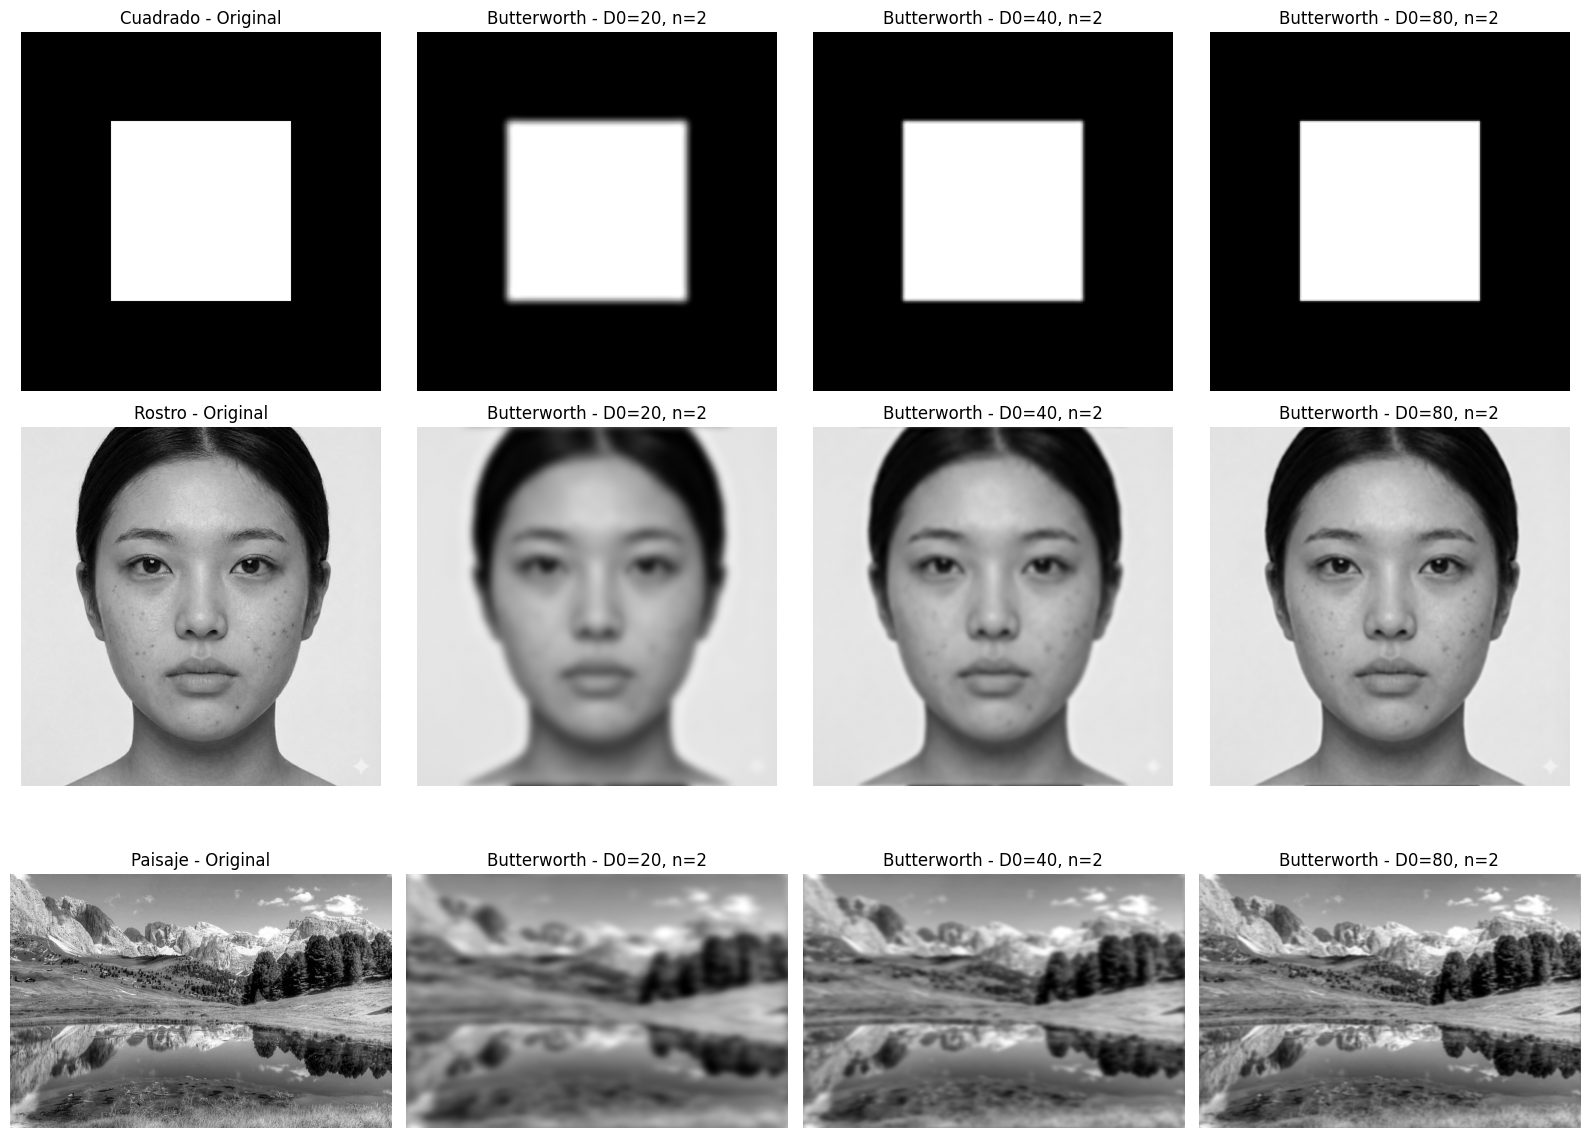

In [20]:
fig, axs = plt.subplots(3, 4, figsize=(16, 12))

for i, (titulo, imagen_actual) in enumerate(
    zip(titulos, imagenes)
):

    axs[i, 0].imshow(
        imagen_actual,
        cmap="gray",
        vmin=0,
        vmax=255
    )
    axs[i, 0].set_title(f"{titulo} - Original")
    axs[i, 0].axis("off")

    for j, corte in enumerate(frecuencias):

        imagen_filtrada = resultados_butterworth[
            titulo
        ][corte]["imagen"]

        axs[i, j + 1].imshow(
            imagen_filtrada,
            cmap="gray",
            vmin=0,
            vmax=255
        )

        axs[i, j + 1].set_title(
            f"Butterworth - D0={corte}, n={orden}"
        )
        axs[i, j + 1].axis("off")

plt.tight_layout()
plt.savefig("results/filtro_butterworth_paso_bajo.png")
plt.show()

### Variando orden prueba

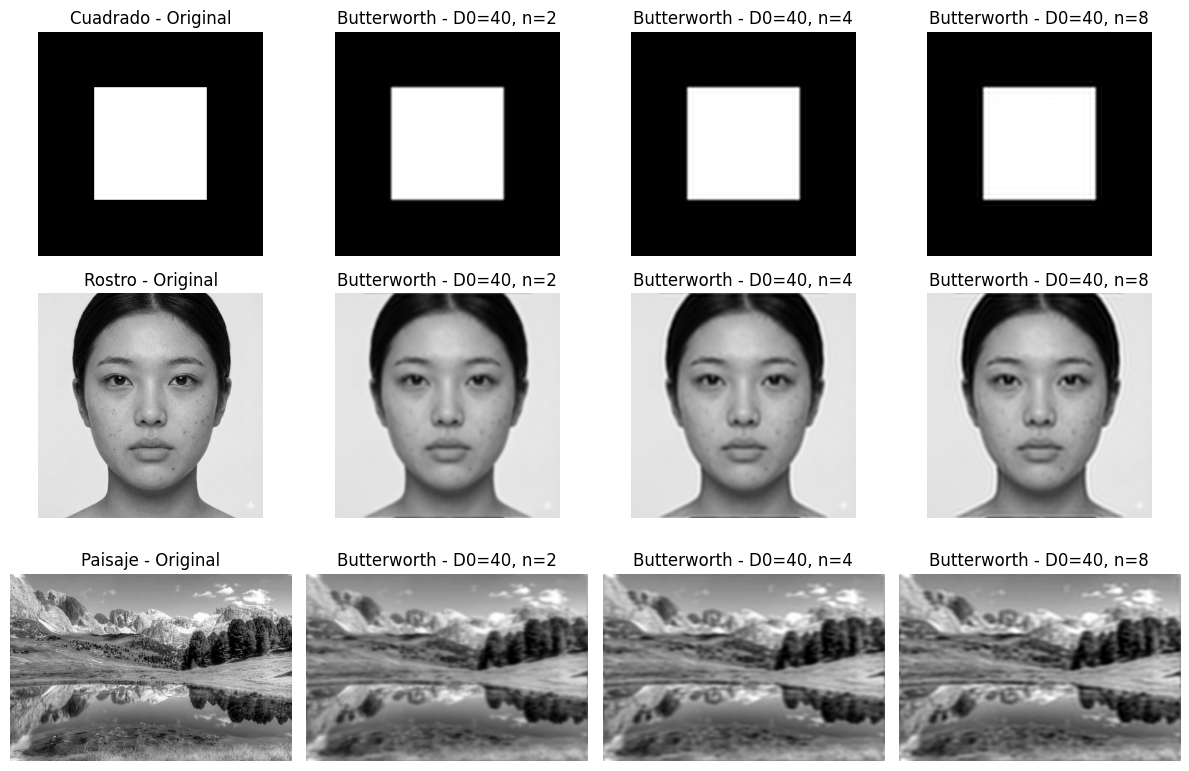

In [26]:
frecuencia_corte = 40
ordenes = [2, 4, 8]

fig, axs = plt.subplots(3, 4, figsize=(12, 8))

for i, (titulo, imagen_actual) in enumerate(
    zip(titulos, imagenes)
):

    axs[i, 0].imshow(
        imagen_actual,
        cmap="gray",
        vmin=0,
        vmax=255
    )
    axs[i, 0].set_title(f"{titulo} - Original")
    axs[i, 0].axis("off")

    for j, orden in enumerate(ordenes):

        filtrada, mascara = filtro_butterworth_paso_bajo(
            imagen_actual,
            frecuencia_corte,
            orden
        )

        axs[i, j + 1].imshow(
            filtrada,
            cmap="gray",
            vmin=0,
            vmax=255
        )

        axs[i, j + 1].set_title(
            f"Butterworth - D0=40, n={orden}"
        )
        axs[i, j + 1].axis("off")

plt.tight_layout()
plt.savefig("results/filtro_butterworth_varios_ordenes.png")
plt.show()

### Análisis de resultados — Punto 2: Filtro Butterworth paso bajo

Se implementó un filtro Butterworth paso bajo en el dominio de la frecuencia mediante una función que recibe la imagen original, la frecuencia de corte y el orden del filtro. La máscara se construyó utilizando ciclos anidados y calculando una ganancia para cada componente de frecuencia según su distancia al centro del espectro.

El algoritmo se probó con tres imágenes: un cuadrado blanco sobre fondo negro, un rostro y un paisaje natural. Se realizaron dos pruebas: primero se modificó la frecuencia de corte, utilizando valores de 20, 40 y 80 con orden 2; posteriormente, se mantuvo una frecuencia de corte de 40 y se compararon los órdenes 2, 4 y 8.

**Variación de la frecuencia de corte**

Al utilizar una frecuencia de corte de 20, las tres imágenes presentan un suavizado considerable. En el cuadrado se pierde definición de los bordes, en el rostro se reducen pequeñas variaciones de intensidad de la piel y en el paisaje desaparecen detalles finos de las montañas, los árboles y sus reflejos.

Al aumentar la frecuencia de corte a 40 y 80, las imágenes recuperan progresivamente su definición. Esto sucede porque el filtro permite conservar una mayor cantidad de componentes de frecuencia, incluyendo aquellas relacionadas con los detalles y bordes.

**Variación del orden**

Al mantener la frecuencia de corte en 40 y aumentar el orden de 2 a 4 y 8, se observa un cambio en la definición de los contornos y en la aparición de pequeñas oscilaciones.

En el cuadrado, con orden 2 los bordes se presentan suavizados y relativamente uniformes, mientras que con orden 8 se distinguen líneas tenues alrededor de los contornos. En el rostro también se observan algunas bandas cerca del contorno de la cabeza y el cuello. En el paisaje, las diferencias son menos notorias, aunque existen pequeñas variaciones en los detalles y bordes.

Este comportamiento ocurre porque, al aumentar el orden, la transición entre las frecuencias conservadas y atenuadas se vuelve más abrupta, aproximándose al filtro ideal y favoreciendo la aparición de oscilaciones.

**En conclusión**, el filtro Butterworth paso bajo permite controlar el suavizado de una imagen mediante la frecuencia de corte y el orden. Una frecuencia de corte mayor conserva más detalles, mientras que el orden determina qué tan gradual o abrupta es la transición del filtro. Los resultados muestran que aumentar el orden no siempre mejora visualmente la imagen, ya que también puede producir artefactos alrededor de los bordes.

## Punto 3
3. Desarrollar una función basada en ciclos que permita
aplicar un filtro Gaussian en 2D. Recibe como
entrada la imagen original y la frecuencia de corte.
Probar el algoritmo con las imágenes “rectOne.pgm”,
“nebulosaLira.pgm” y “gwen-pgm” con diversas
frecuencias de corte.

In [28]:
def filtro_gaussiano_paso_bajo(imagen, frecuencia_corte):
    if frecuencia_corte <= 0:
        raise ValueError("La frecuencia de corte debe ser mayor que cero.")

    # Dimensiones de la imagen
    filas, columnas = imagen.shape

    # Paso 1: Transformada de Fourier de la imagen
    transformada = np.fft.fft2(imagen)

    # Centrar las frecuencias
    transformada_centrada = np.fft.fftshift(transformada)

    # Paso 2: Crear el filtro Gaussiano de paso bajo
    mascara = np.zeros((filas, columnas), dtype=np.float64)

    # Calcular el centro de la imagen
    centro_fila, centro_columna = filas // 2, columnas // 2

    # Paso 3: Calcular la máscara del filtro Gaussiano
    for fila in range(filas):
        for columna in range(columnas):
            # Calcular la distancia desde el centro
            distancia = np.sqrt((fila - centro_fila) ** 2 + (columna - centro_columna) ** 2)
            # Aplicar la fórmula del filtro Gaussiano
            mascara[fila, columna] = np.exp(-(distancia ** 2) / (2 * (frecuencia_corte ** 2)))

    # Paso 4: Aplicar el filtro a la transformada centrada
    transformada_filtrada = transformada_centrada * mascara

    # Paso 5: Transformada inversa de Fourier, regresar al dominio espacial
    transformada_inversa = np.fft.ifftshift(transformada_filtrada)

    imagen_filtrada = np.fft.ifft2(transformada_inversa)

    # Obtener la parte real de la imagen filtrada
    imagen_filtrada_real = np.real(imagen_filtrada)

    return imagen_filtrada_real, mascara

In [29]:
frecuencias = [20, 40, 80]

resultados_gaussiano = {}

for titulo, imagen_actual in zip(titulos, imagenes):

    resultados_gaussiano[titulo] = {}

    for corte in frecuencias:

        filtrada, mascara = filtro_gaussiano_paso_bajo(
            imagen_actual, corte
        )

        resultados_gaussiano[titulo][corte] = {
            "imagen": filtrada,
            "mascara": mascara
        }

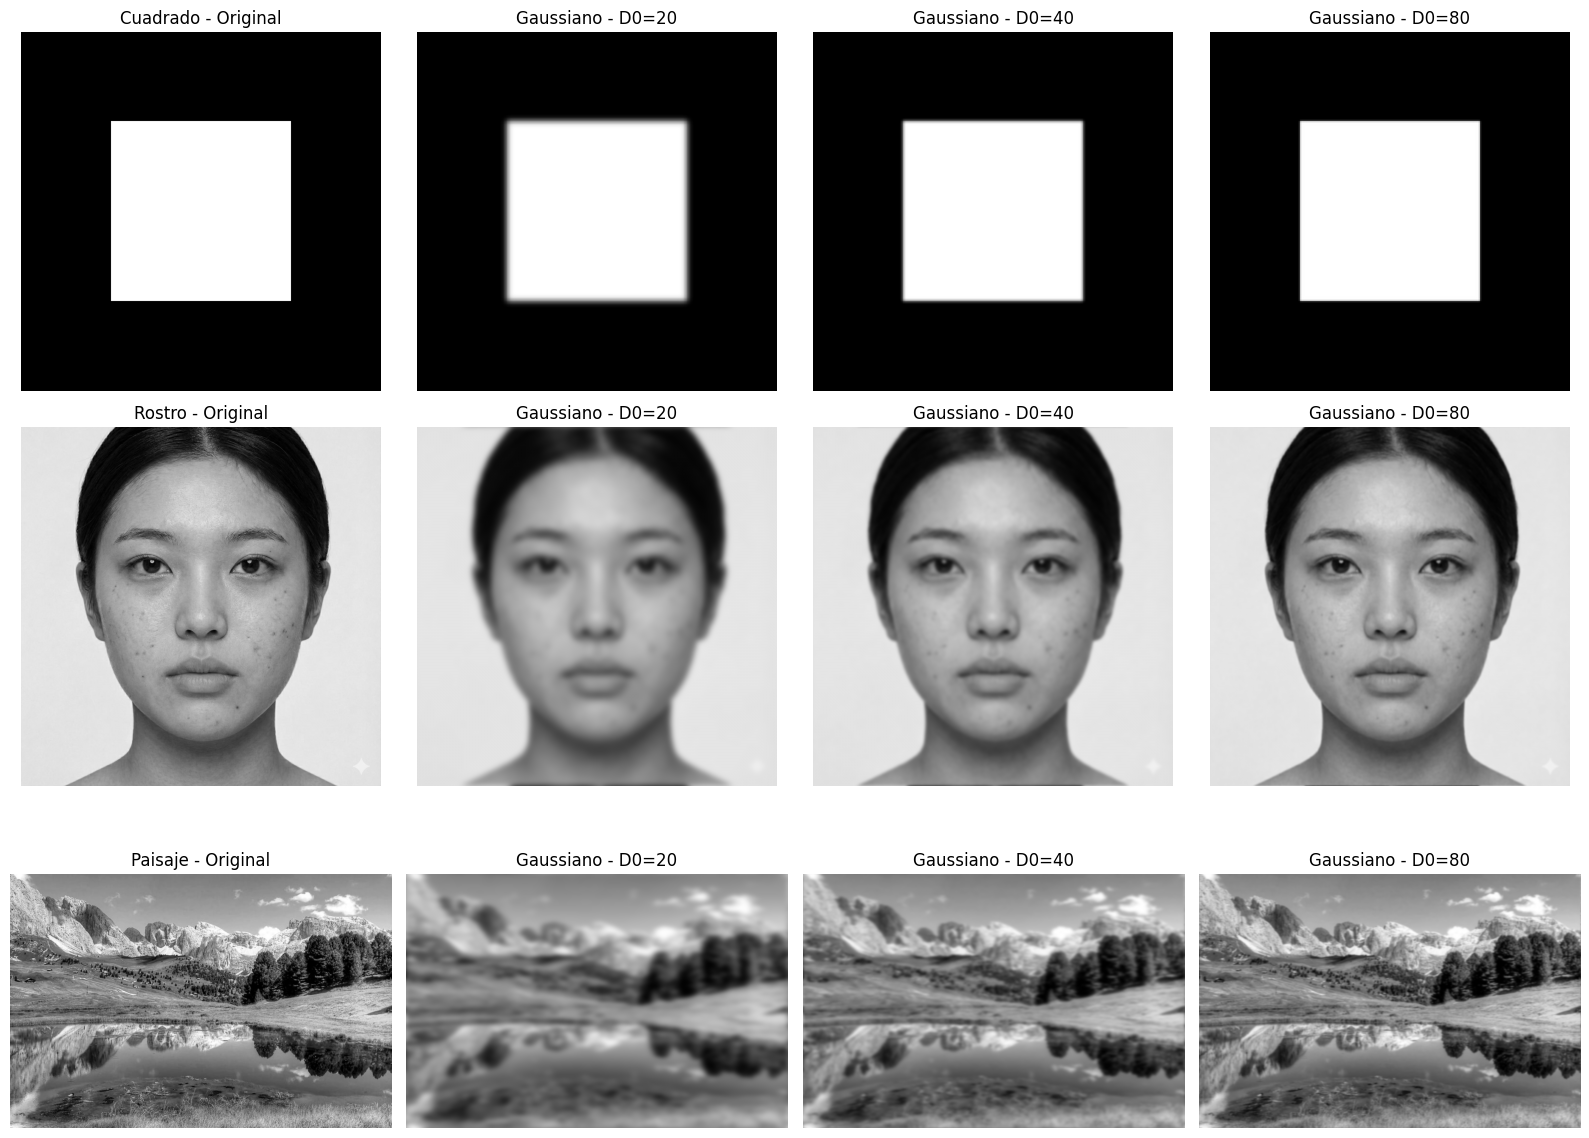

In [31]:
fig, axs = plt.subplots(3, 4, figsize=(16, 12))

for i, (titulo, imagen_actual) in enumerate(
    zip(titulos, imagenes)
):
    axs[i, 0].imshow(
        imagen_actual,
        cmap="gray",
        vmin=0,
        vmax=255
    )
    axs[i, 0].set_title(f"{titulo} - Original")
    axs[i, 0].axis("off")

    for j, corte in enumerate(frecuencias):

        filtrada = resultados_gaussiano[titulo][corte]["imagen"]

        axs[i, j + 1].imshow(
            filtrada,
            cmap="gray",
            vmin=0,
            vmax=255
        )

        axs[i, j + 1].set_title(
            f"Gaussiano - D0={corte}"
        )
        axs[i, j + 1].axis("off")

plt.tight_layout()
plt.savefig("results/filtro_gaussiano_paso_bajo.png")
plt.show()

### Análisis de resultados — Punto 3: Filtro Gaussiano paso bajo

Se implementó un filtro Gaussiano paso bajo en el dominio de la frecuencia mediante una función que recibe una imagen en escala de grises y una frecuencia de corte. La máscara se construyó utilizando ciclos anidados, calculando una ganancia para cada componente de frecuencia según su distancia al centro del espectro.

El algoritmo se probó con tres imágenes: un cuadrado blanco sobre fondo negro, un rostro y un paisaje natural, utilizando frecuencias de corte de 20, 40 y 80.

En la imagen del **cuadrado**, se observa que con una frecuencia de corte de 20 los bordes presentan un suavizado considerable, mientras que con 40 y 80 recuperan progresivamente su definición. Las transiciones entre el cuadrado y el fondo son graduales y no se aprecian oscilaciones pronunciadas alrededor de los contornos.

En el **rostro**, el filtro con frecuencia de corte de 20 reduce notablemente las pequeñas variaciones de intensidad de la piel, pero también afecta la definición de los ojos, las cejas y el cabello. Al aumentar la frecuencia de corte, se recuperan más detalles y la fotografía se aproxima progresivamente a la original.

En el **paisaje**, con una frecuencia de corte de 20 se pierden numerosos detalles de las montañas, los árboles y sus reflejos en el agua. Con 40 se recuperan algunas texturas, mientras que con 80 se conserva una mayor cantidad de detalles y contornos.

Estos resultados se deben a que el filtro Gaussiano atenúa progresivamente las frecuencias altas. Una frecuencia de corte pequeña genera un suavizado mayor, mientras que una frecuencia de corte más alta permite conservar más detalles.

**En conclusión**, el filtro Gaussiano paso bajo permite suavizar imágenes mediante una atenuación gradual de las frecuencias altas. En los resultados obtenidos, produjo transiciones suaves sin oscilaciones pronunciadas alrededor de los bordes, aunque un suavizado intenso también ocasiona pérdida de detalles importantes.

## Punto 4

4. Desarrollar una función basada en ciclos que permita
aplicar un filtro ideal pasa altos en 2D. Recibe como
entrada la imagen original y la frecuencia de corte.
Probar el algoritmo con las imágenes “rectOne.pgm”,
“nebulosaLira.pgm” y “gwen-pgm” con diversas
frecuencias de corte.

In [33]:
def filtro_ideal_paso_alto(imagen, frecuencia_corte):
    if frecuencia_corte <= 0:
        raise ValueError("La frecuencia de corte debe ser mayor que cero.")

    # Dimensiones de la imagen
    filas, columnas = imagen.shape

    # Paso 1: Transformada de Fourier de la imagen
    transformada = np.fft.fft2(imagen)

    # Centrar las frecuencias
    transformada_centrada = np.fft.fftshift(transformada)

    # Paso 2: Crear el filtro ideal de paso alto
    mascara = np.ones((filas, columnas), dtype=np.float64) # Aqui la mascara es inicializada en 1, vamos a reemplazar las frecuencias bajas por 0

    # Calcular el centro de la imagen
    centro_fila, centro_columna = filas // 2, columnas // 2

    for fila in range(filas):
        for columna in range(columnas):
            # Calcular la distancia desde el centro
            distancia = np.sqrt((fila - centro_fila) ** 2 + (columna - centro_columna) ** 2)
            if distancia <= frecuencia_corte:
                mascara[fila, columna] = 0 # Aqui se establece en 0 para las frecuencias bajas

    # Paso 3: Aplicar el filtro a la transformada centrada
    transformada_filtrada = transformada_centrada * mascara

    # Paso 4: Transformada inversa de Fourier, regresar al dominio espacial
    transformada_inversa = np.fft.ifftshift(transformada_filtrada)

    imagen_filtrada = np.fft.ifft2(transformada_inversa)

    # Paso 5: Tomar la parte real de la imagen filtrada
    imagen_filtrada_real = np.real(imagen_filtrada)

    return imagen_filtrada_real, mascara

In [34]:
frecuencias = [20, 40, 80]

resultados_paso_alto = {}

for titulo, imagen_actual in zip(titulos, imagenes):

    resultados_paso_alto[titulo] = {}

    for corte in frecuencias:

        filtrada, mascara = filtro_ideal_paso_alto(
            imagen_actual, corte
        )

        resultados_paso_alto[titulo][corte] = {
            "imagen": filtrada,
            "mascara": mascara
        }

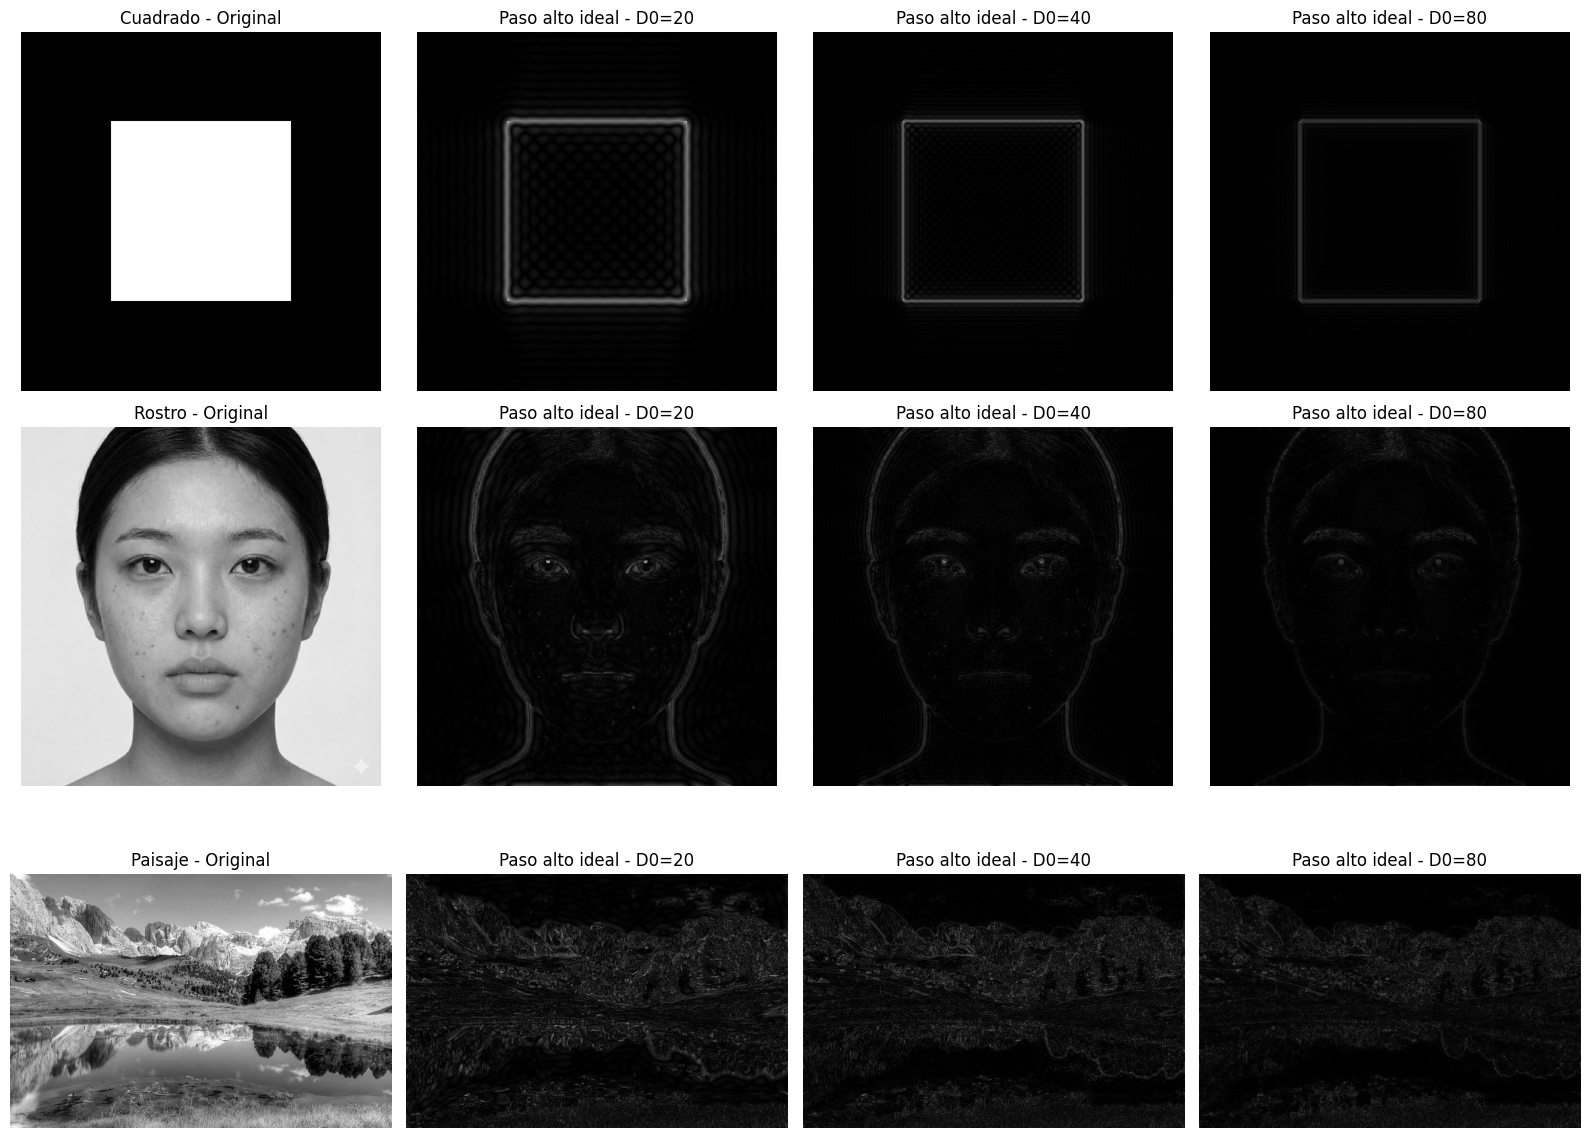

In [35]:
fig, axs = plt.subplots(3, 4, figsize=(16, 12))

for i, (titulo, imagen_actual) in enumerate(
    zip(titulos, imagenes)
):

    axs[i, 0].imshow(
        imagen_actual,
        cmap="gray",
        vmin=0,
        vmax=255
    )
    axs[i, 0].set_title(f"{titulo} - Original")
    axs[i, 0].axis("off")

    for j, corte in enumerate(frecuencias):

        filtrada = resultados_paso_alto[titulo][corte]["imagen"]

        axs[i, j + 1].imshow(
            np.abs(filtrada),
            cmap="gray",
            vmin=0,
            vmax=255
        )

        axs[i, j + 1].set_title(
            f"Paso alto ideal - D0={corte}"
        )
        axs[i, j + 1].axis("off")

plt.tight_layout()
plt.savefig("results/filtro_ideal_paso_alto.png")
plt.show()

### Análisis de resultados — Punto 4: Filtro ideal paso alto

Se implementó un filtro ideal paso alto en el dominio de la frecuencia mediante una función que recibe una imagen en escala de grises y una frecuencia de corte. La máscara se construyó utilizando ciclos anidados, asignando un valor de cero a las frecuencias ubicadas dentro del radio de corte y uno a las restantes.

El algoritmo se aplicó a tres imágenes: un cuadrado blanco sobre fondo negro, un rostro y un paisaje natural, utilizando frecuencias de corte de 20, 40 y 80. Para visualizar los resultados se utilizó el valor absoluto de las respuestas y una escala fija de intensidad entre 0 y 255.

En la imagen del **cuadrado**, con una frecuencia de corte de 20 se observan claramente sus contornos, acompañados de oscilaciones alrededor de los bordes y dentro de la figura. Al aumentar la frecuencia de corte a 40 y 80, los contornos aparecen progresivamente más tenues y disminuye la cantidad de detalles visibles.

En el **rostro**, con una frecuencia de corte de 20 se distinguen los contornos de los ojos, la nariz, los labios, el cabello y la silueta de la cabeza. También aparecen bandas alrededor del rostro. Con frecuencias de corte mayores, la imagen se vuelve más oscura y permanecen principalmente algunas variaciones finas de intensidad.

En el **paisaje**, el filtro permite resaltar contornos de montañas, árboles, vegetación y reflejos en el agua. Con una frecuencia de corte de 20 estas estructuras son más visibles, mientras que con valores de 40 y 80 se reduce progresivamente la intensidad de las respuestas.

Este comportamiento ocurre porque el filtro paso alto elimina las frecuencias bajas. Al aumentar la frecuencia de corte, se amplía la región de frecuencias eliminadas, conservando únicamente componentes cada vez más altas.

También se observó el **efecto de anillado**, especialmente alrededor del cuadrado y del rostro, debido al corte abrupto de frecuencias característico del filtro ideal.

**En conclusión**, el filtro ideal paso alto permite destacar variaciones rápidas de intensidad, como bordes y texturas. Sin embargo, al aumentar la frecuencia de corte se eliminan más componentes y las respuestas pueden perder intensidad visual. Además, el corte abrupto puede generar oscilaciones alrededor de los contornos.